# NEPSE Next-Day Stock Direction Prediction
**CSC61304: Machine Learning and Intelligent Systems**


## 1. Imports and load data

In [13]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import TimeSeriesSplit, RandomizedSearchCV
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, roc_auc_score, confusion_matrix,
                             ConfusionMatrixDisplay, roc_curve,
                             classification_report)
from xgboost import XGBClassifier

sns.set_style("whitegrid")
RANDOM_STATE = 42

df = pd.read_csv("nepse_prices.csv", parse_dates=["date"])   # change path if needed
print("Shape:", df.shape)
df.head()

Shape: (531245, 16)


,date,symbol,company_name,sector,open,high,low,close,pct_change,volume,turnover,adj_open,adj_high,adj_low,adj_close,adjustments
0,1995-07-20,BBC,Bishal Bazar Company Limited,Trading,2220.0,2220.0,2220.0,2220.0,0.0,560.0,0.0,2220.0,2220.0,2220.0,2220.0,NaN
1,1995-07-26,BBC,Bishal Bazar Company Limited,Trading,2220.0,2442.0,2442.0,2442.0,0.0,150.0,0.0,2220.0,2442.0,2442.0,2442.0,NaN
2,1995-07-30,BBC,Bishal Bazar Company Limited,Trading,2442.0,2500.0,2500.0,2500.0,0.0,200.0,0.0,2442.0,2500.0,2500.0,2500.0,NaN
3,1995-08-02,BBC,Bishal Bazar Company Limited,Trading,2500.0,2501.0,2501.0,2501.0,0.0,18.0,0.0,2500.0,2501.0,2501.0,2501.0,NaN
4,1995-08-06,BBC,Bishal Bazar Company Limited,Trading,2501.0,2500.0,2500.0,2500.0,0.0,40.0,0.0,2501.0,2500.0,2500.0,2500.0,NaN


## 2. EDA - structure, missing values, duplicates

In [14]:
print(df.info())
print("\nMissing values:\n", df.isna().sum())          
print("\nDuplicate rows:", df.duplicated().sum())
print("Date range:", df["date"].min(), "->", df["date"].max())
print("Symbols:", df["symbol"].nunique(), "| Sectors:", df["sector"].nunique())
df.describe().T

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 531245 entries, 0 to 531244
Data columns (total 16 columns):
 #   Column        Non-Null Count   Dtype         
---  ------        --------------   -----         
 0   date          531245 non-null  datetime64[ns]
 1   symbol        531245 non-null  object        
 2   company_name  531245 non-null  object        
 3   sector        531245 non-null  object        
 4   open          531245 non-null  float64       
 5   high          531245 non-null  float64       
 6   low           531245 non-null  float64       
 7   close         531245 non-null  float64       
 8   pct_change    531245 non-null  float64       
 9   volume        531245 non-null  float64       
 10  turnover      531245 non-null  float64       
 11  adj_open      531245 non-null  float64       
 12  adj_high      531245 non-null  float64       
 13  adj_low       531245 non-null  float64       
 14  adj_close     531245 non-null  float64       
 15  adjustments   291

,count,mean,min,25%,50%,75%,max,std
date,531245,2021-12-31 19:51:36.124009728,1995-07-20 00:00:00,2019-08-13 00:00:00,2023-01-25 00:00:00,2025-02-03 00:00:00,2026-11-13 00:00:00,NaN
open,531245.0,926.496926,0.0,247.0,484.0,901.9,55080.0,2442.186352
high,531245.0,940.787597,0.0,251.8,494.0,916.5,56805.8,2466.967289
low,531245.0,913.36376,0.0,242.1,475.1,890.0,53400.0,2417.462257
close,531245.0,926.793198,0.0,247.0,484.0,902.0,55000.0,2440.2997
pct_change,531245.0,0.070729,-77.55,-0.98,0.0,0.72,531.25,2.628208
volume,531245.0,36252.215204,0.0,1463.0,7635.0,28966.0,14006230.0,119917.004119
turnover,531245.0,15306222.311266,0.0,454117.0,3258053.0,12484110.1,2012993143.0,42965629.278133
adj_open,531245.0,1359.689456,0.0,156.49,337.71,658.71,1091071.04,26222.489866
adj_high,531245.0,1370.80103,0.0,158.79,344.32,670.35,1091095.07,26224.465255


## 3. EDA - visualisations

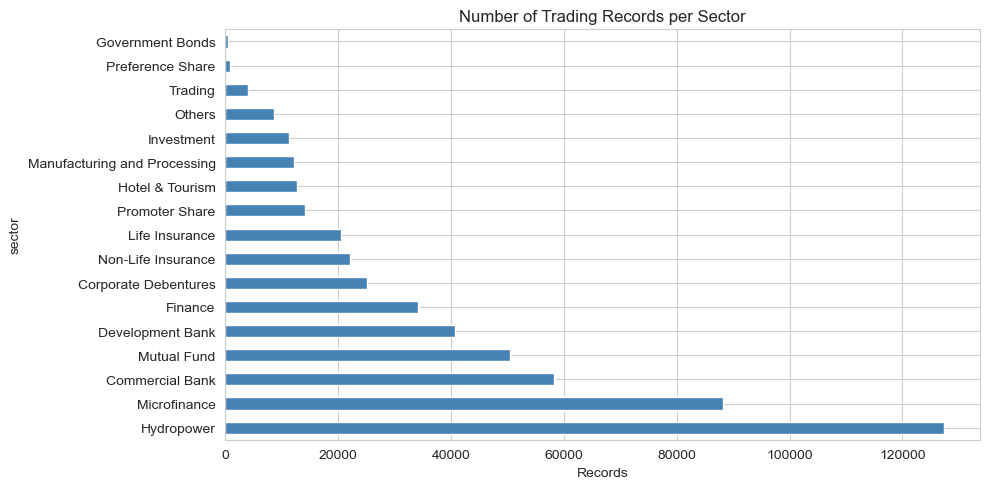

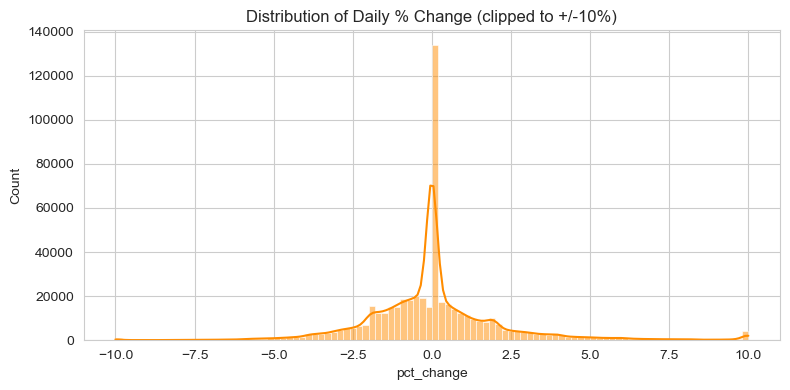

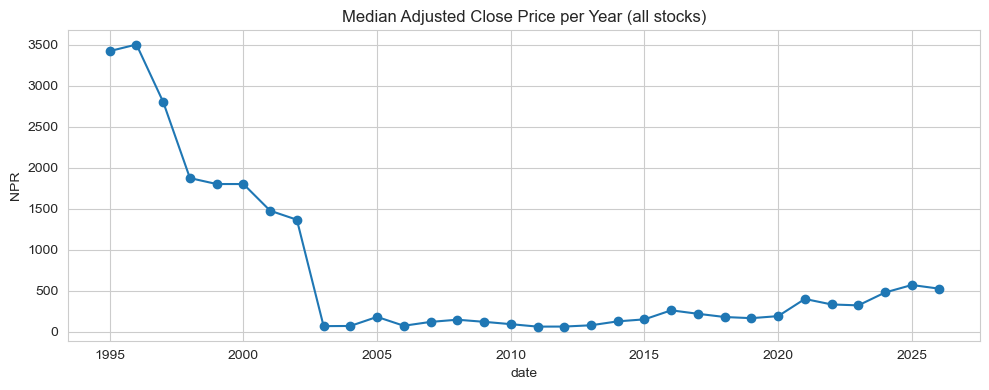

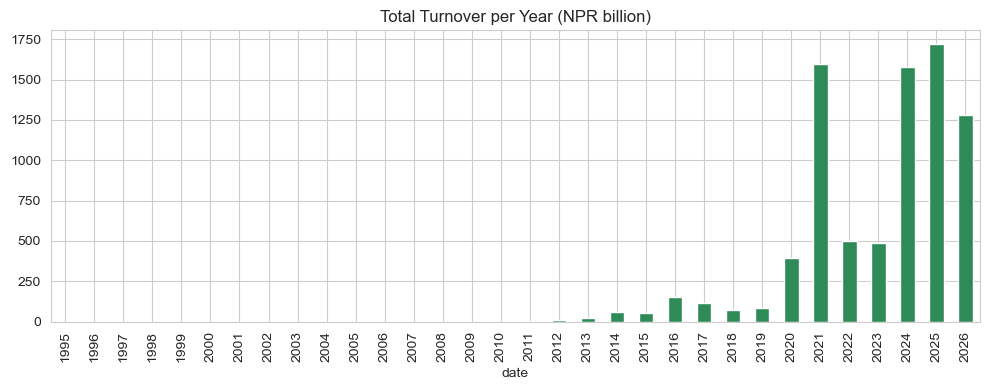

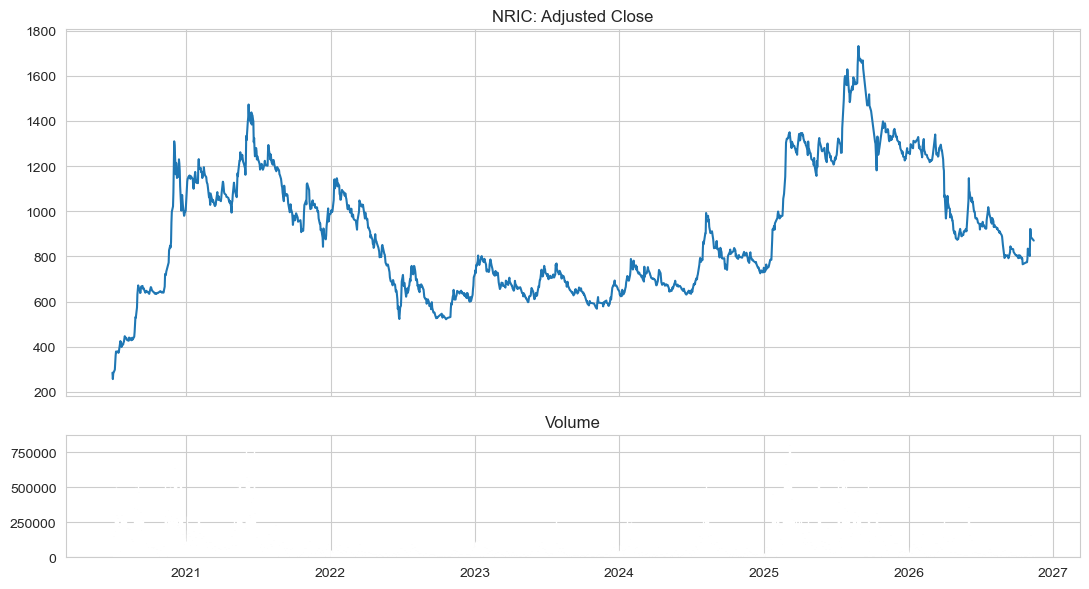

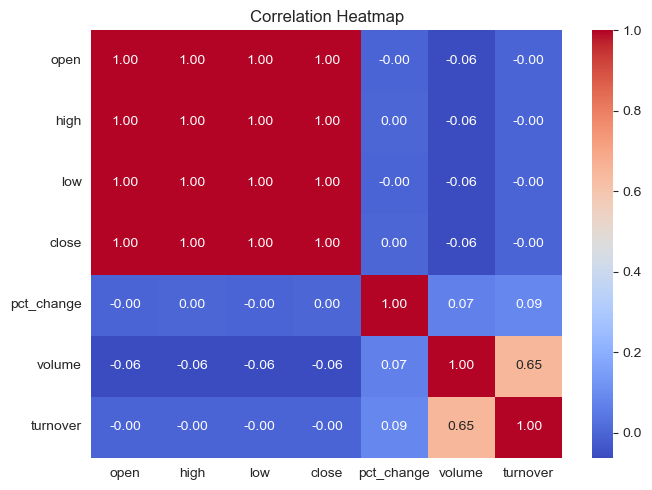

In [15]:

plt.figure(figsize=(10, 5))
df["sector"].value_counts().plot(kind="barh", color="steelblue")
plt.title("Number of Trading Records per Sector")
plt.xlabel("Records")
plt.tight_layout(); plt.show()

plt.figure(figsize=(8, 4))
sns.histplot(df["pct_change"].clip(-10, 10), bins=100, kde=True, color="darkorange")
plt.title("Distribution of Daily % Change (clipped to +/-10%)")
plt.tight_layout(); plt.show()

yearly = df.groupby(df["date"].dt.year)["adj_close"].median()
plt.figure(figsize=(10, 4))
yearly.plot(marker="o")
plt.title("Median Adjusted Close Price per Year (all stocks)")
plt.ylabel("NPR"); plt.tight_layout(); plt.show()

turn = df.groupby(df["date"].dt.year)["turnover"].sum() / 1e9
plt.figure(figsize=(10, 4))
turn.plot(kind="bar", color="seagreen")
plt.title("Total Turnover per Year (NPR billion)")
plt.tight_layout(); plt.show()

top_symbol = df.groupby("symbol")["turnover"].sum().idxmax()
s = df[df["symbol"] == top_symbol].sort_values("date")
fig, ax = plt.subplots(2, 1, figsize=(11, 6), sharex=True,
                       gridspec_kw={"height_ratios": [3, 1]})
ax[0].plot(s["date"], s["adj_close"]); ax[0].set_title(f"{top_symbol}: Adjusted Close")
ax[1].bar(s["date"], s["volume"], color="gray"); ax[1].set_title("Volume")
plt.tight_layout(); plt.show()

num_cols = ["open", "high", "low", "close", "pct_change", "volume", "turnover"]
plt.figure(figsize=(7, 5))
sns.heatmap(df[num_cols].corr(), annot=True, fmt=".2f", cmap="coolwarm")
plt.title("Correlation Heatmap"); plt.tight_layout(); plt.show()

## 4. Data cleaning

In [16]:
d = df.copy()
d = d.drop_duplicates()
d = d[(d["adj_close"] > 0) & (d["volume"] > 0)]            
d = d[d["date"] >= "2015-01-01"]                            
d = d.sort_values(["symbol", "date"]).reset_index(drop=True)

top50 = d.groupby("symbol")["turnover"].sum().nlargest(50).index
d = d[d["symbol"].isin(top50)].reset_index(drop=True)
print("After cleaning:", d.shape)

After cleaning: (111425, 16)


## 5. Feature engineering (done per stock using ADJUSTED prices)

In [17]:
def rsi(series, n=14):
    delta = series.diff()
    gain = delta.clip(lower=0).rolling(n).mean()
    loss = (-delta.clip(upper=0)).rolling(n).mean()
    return 100 - 100 / (1 + gain / (loss + 1e-9))

def add_features(g):
    g = g.copy()
    c = g["adj_close"]
    g["ret_1"] = c.pct_change(1)
    g["ret_3"] = c.pct_change(3)
    g["ret_5"] = c.pct_change(5)
    g["ret_10"] = c.pct_change(10)
    g["ma_5_ratio"] = c / c.rolling(5).mean()
    g["ma_20_ratio"] = c / c.rolling(20).mean()
    g["volatility_10"] = g["ret_1"].rolling(10).std()
    g["rsi_14"] = rsi(c)
    g["hl_range"] = (g["adj_high"] - g["adj_low"]) / c
    g["oc_change"] = (g["adj_close"] - g["adj_open"]) / g["adj_open"]
    g["vol_ratio"] = g["volume"] / (g["volume"].rolling(10).mean() + 1e-9)
    g["log_turnover"] = np.log1p(g["turnover"])

    g["target"] = (c.shift(-1) > c).astype(int)
    
    g["next_date_valid"] = c.shift(-1).notna() & (c.shift(-1) != c)
    return g

d = d.groupby("symbol", group_keys=False).apply(add_features)
d["sector_code"] = d["sector"].astype("category").cat.codes
d = d[d["next_date_valid"]].replace([np.inf, -np.inf], np.nan).dropna().reset_index(drop=True)

features = ["ret_1", "ret_3", "ret_5", "ret_10", "ma_5_ratio", "ma_20_ratio",
            "volatility_10", "rsi_14", "hl_range", "oc_change", "vol_ratio",
            "log_turnover", "sector_code"]
print("Rows for modelling:", d.shape[0])
print("Target balance:\n", d["target"].value_counts(normalize=True))

Rows for modelling: 83404
Target balance:
 target
0    0.5467
1    0.4533
Name: proportion, dtype: float64


## 6. Feature selection (correlation with target + RF importance preview)

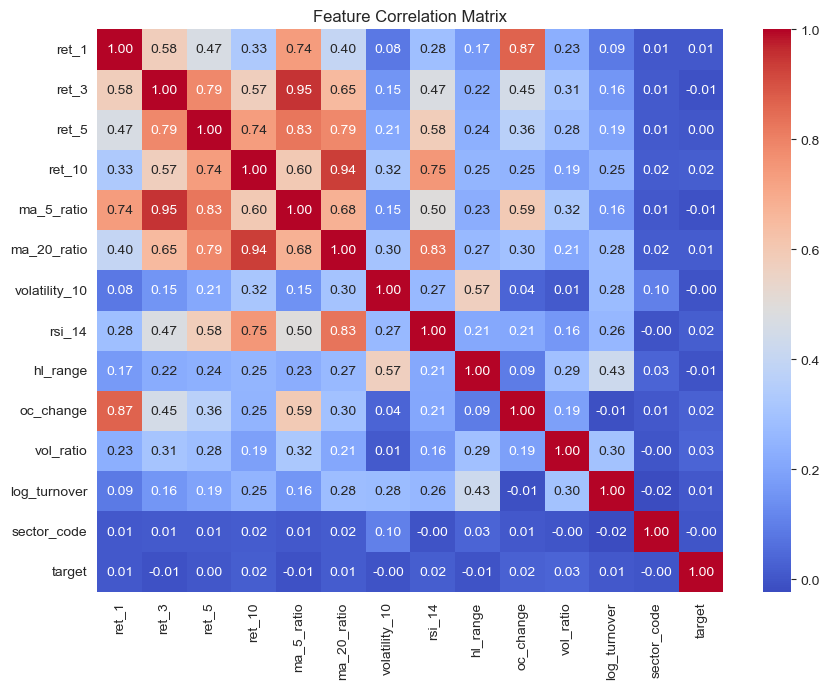

Dropped (highly correlated): ['ma_5_ratio', 'ma_20_ratio']
Final features: ['ret_1', 'ret_3', 'ret_5', 'ret_10', 'volatility_10', 'rsi_14', 'hl_range', 'oc_change', 'vol_ratio', 'log_turnover', 'sector_code']


In [18]:
plt.figure(figsize=(9, 7))
sns.heatmap(d[features + ["target"]].corr(), annot=True, fmt=".2f", cmap="coolwarm")
plt.title("Feature Correlation Matrix"); plt.tight_layout(); plt.show()

corr = d[features].corr().abs()
upper = corr.where(np.triu(np.ones(corr.shape), k=1).astype(bool))
to_drop = [c for c in upper.columns if any(upper[c] > 0.9)]
features = [f for f in features if f not in to_drop]
print("Dropped (highly correlated):", to_drop)
print("Final features:", features)

## 7. Train/test split (TIME-BASED: never shuffle stock data!)

In [19]:
d = d.sort_values("date").reset_index(drop=True)
split_date = d["date"].quantile(0.80)
train = d[d["date"] <= split_date]
test = d[d["date"] > split_date]

X_train, y_train = train[features], train["target"]
X_test, y_test = test[features], test["target"]
print(f"Train: {X_train.shape}  ({train['date'].min().date()} -> {train['date'].max().date()})")
print(f"Test : {X_test.shape}  ({test['date'].min().date()} -> {test['date'].max().date()})")

Train: (66755, 11)  (2015-02-01 -> 2023-09-07)
Test : (16649, 11)  (2023-09-10 -> 2026-10-27)


## 8. Baseline models (default parameters)

In [20]:
rf = RandomForestClassifier(n_estimators=200, random_state=RANDOM_STATE, n_jobs=-1)
xgb = XGBClassifier(n_estimators=200, random_state=RANDOM_STATE, n_jobs=-1,
                    eval_metric="logloss")
rf.fit(X_train, y_train)
xgb.fit(X_train, y_train)

def evaluate(model, name):
    pred = model.predict(X_test)
    proba = model.predict_proba(X_test)[:, 1]
    return {"Model": name,
            "Accuracy": accuracy_score(y_test, pred),
            "Precision": precision_score(y_test, pred),
            "Recall": recall_score(y_test, pred),
            "F1": f1_score(y_test, pred),
            "ROC-AUC": roc_auc_score(y_test, proba)}

baseline = pd.DataFrame([evaluate(rf, "Random Forest (default)"),
                         evaluate(xgb, "XGBoost (default)")])
baseline

,Model,Accuracy,Precision,Recall,F1,ROC-AUC
0,Random Forest (default),0.547600,0.513129,0.278759,0.361262,0.544765
1,XGBoost (default),0.534687,0.490011,0.340270,0.401637,0.537785


## 9. Hyperparameter tuning (RandomizedSearchCV + TimeSeriesSplit)

In [21]:
tscv = TimeSeriesSplit(n_splits=3)      

rf_params = {
    "n_estimators": [100, 200, 300, 500],
    "max_depth": [5, 10, 15, 20, None],
    "min_samples_split": [2, 5, 10, 20],
    "min_samples_leaf": [1, 2, 5, 10],
    "max_features": ["sqrt", "log2", 0.5],
}
xgb_params = {
    "n_estimators": [100, 200, 300, 500],
    "max_depth": [3, 4, 5, 6, 8],
    "learning_rate": [0.01, 0.03, 0.05, 0.1, 0.2],
    "subsample": [0.6, 0.8, 1.0],
    "colsample_bytree": [0.6, 0.8, 1.0],
    "gamma": [0, 0.1, 0.3, 1],
}

rf_search = RandomizedSearchCV(
    RandomForestClassifier(random_state=RANDOM_STATE, n_jobs=-1),
    rf_params, n_iter=15, scoring="roc_auc", cv=tscv,
    random_state=RANDOM_STATE, n_jobs=-1, verbose=1)
xgb_search = RandomizedSearchCV(
    XGBClassifier(random_state=RANDOM_STATE, n_jobs=-1, eval_metric="logloss"),
    xgb_params, n_iter=15, scoring="roc_auc", cv=tscv,
    random_state=RANDOM_STATE, n_jobs=-1, verbose=1)

rf_search.fit(X_train, y_train)
xgb_search.fit(X_train, y_train)

print("Best RF params :", rf_search.best_params_, "| CV AUC:", round(rf_search.best_score_, 4))
print("Best XGB params:", xgb_search.best_params_, "| CV AUC:", round(xgb_search.best_score_, 4))

rf_cv = pd.DataFrame(rf_search.cv_results_).sort_values("rank_test_score")
xgb_cv = pd.DataFrame(xgb_search.cv_results_).sort_values("rank_test_score")
rf_cv[["params", "mean_test_score", "std_test_score", "rank_test_score"]].head(5)

Fitting 3 folds for each of 15 candidates, totalling 45 fits
Fitting 3 folds for each of 15 candidates, totalling 45 fits
Best RF params : {'n_estimators': 200, 'min_samples_split': 20, 'min_samples_leaf': 2, 'max_features': 'log2', 'max_depth': 15} | CV AUC: 0.5497
Best XGB params: {'subsample': 0.8, 'n_estimators': 500, 'max_depth': 5, 'learning_rate': 0.03, 'gamma': 0, 'colsample_bytree': 0.8} | CV AUC: 0.5484


,params,mean_test_score,std_test_score,rank_test_score
1,"{'n_estimators': 200, 'min_samples_split': 20,...",0.549684,0.008259,1
7,"{'n_estimators': 300, 'min_samples_split': 20,...",0.549559,0.009331,2
2,"{'n_estimators': 300, 'min_samples_split': 20,...",0.549466,0.009403,3
13,"{'n_estimators': 500, 'min_samples_split': 10,...",0.549148,0.010370,4
3,"{'n_estimators': 200, 'min_samples_split': 20,...",0.548844,0.009401,5


## 10. Final evaluation: default vs tuned

In [22]:
best_rf, best_xgb = rf_search.best_estimator_, xgb_search.best_estimator_
results = pd.concat([baseline,
                     pd.DataFrame([evaluate(best_rf, "Random Forest (tuned)"),
                                   evaluate(best_xgb, "XGBoost (tuned)")])],
                    ignore_index=True).round(4)
print(results.to_string(index=False))

                  Model  Accuracy  Precision  Recall     F1  ROC-AUC
Random Forest (default)    0.5476     0.5131  0.2788 0.3613   0.5448
      XGBoost (default)    0.5347     0.4900  0.3403 0.4016   0.5378
  Random Forest (tuned)    0.5533     0.5369  0.1942 0.2852   0.5500
        XGBoost (tuned)    0.5483     0.5187  0.2180 0.3070   0.5459


## 11. Evaluation plots

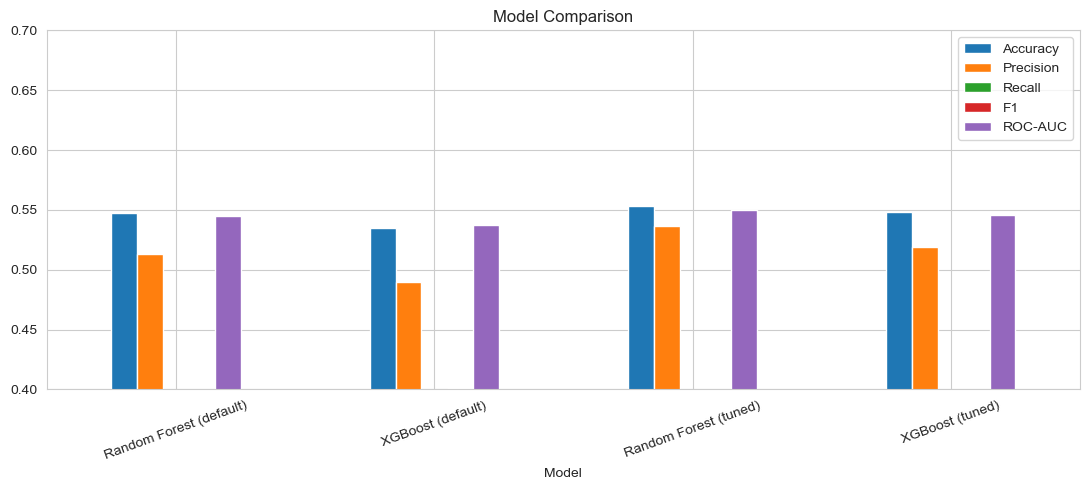

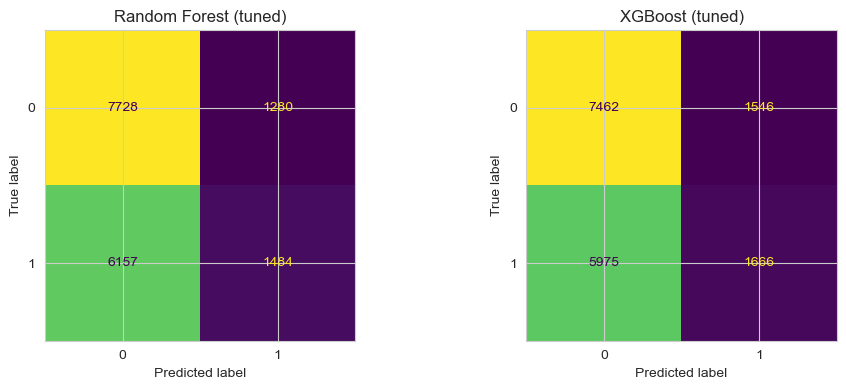

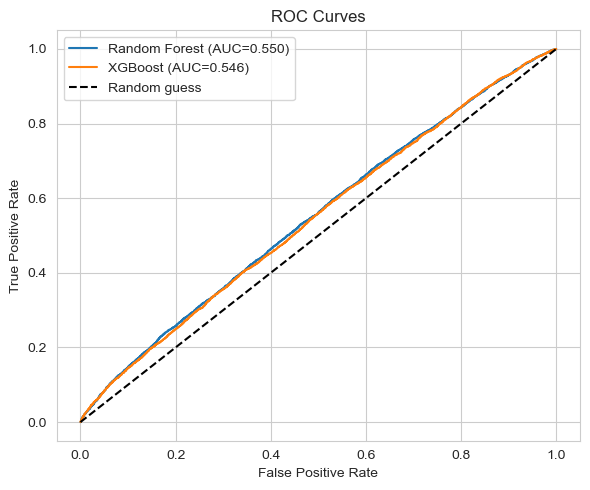

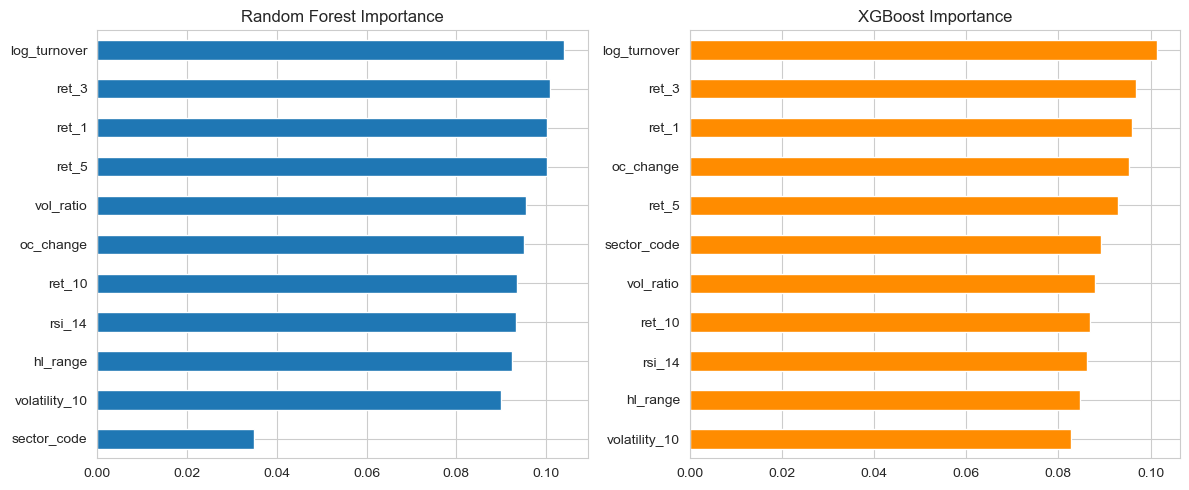

              precision    recall  f1-score   support

        Down       0.56      0.83      0.66      9008
          Up       0.52      0.22      0.31      7641

    accuracy                           0.55     16649
   macro avg       0.54      0.52      0.49     16649
weighted avg       0.54      0.55      0.50     16649



In [23]:

results.set_index("Model")[["Accuracy", "Precision", "Recall", "F1", "ROC-AUC"]].plot(
    kind="bar", figsize=(11, 5), rot=20)
plt.title("Model Comparison"); plt.ylim(0.4, 0.7); plt.tight_layout(); plt.show()

fig, ax = plt.subplots(1, 2, figsize=(10, 4))
for a, (m, n) in zip(ax, [(best_rf, "Random Forest (tuned)"), (best_xgb, "XGBoost (tuned)")]):
    ConfusionMatrixDisplay(confusion_matrix(y_test, m.predict(X_test))).plot(ax=a, colorbar=False)
    a.set_title(n)
plt.tight_layout(); plt.show()

plt.figure(figsize=(6, 5))
for m, n in [(best_rf, "Random Forest"), (best_xgb, "XGBoost")]:
    fpr, tpr, _ = roc_curve(y_test, m.predict_proba(X_test)[:, 1])
    plt.plot(fpr, tpr, label=f"{n} (AUC={roc_auc_score(y_test, m.predict_proba(X_test)[:,1]):.3f})")
plt.plot([0, 1], [0, 1], "k--", label="Random guess")
plt.xlabel("False Positive Rate"); plt.ylabel("True Positive Rate")
plt.title("ROC Curves"); plt.legend(); plt.tight_layout(); plt.show()

fig, ax = plt.subplots(1, 2, figsize=(12, 5))
pd.Series(best_rf.feature_importances_, index=features).sort_values().plot(kind="barh", ax=ax[0])
ax[0].set_title("Random Forest Importance")
pd.Series(best_xgb.feature_importances_, index=features).sort_values().plot(kind="barh", ax=ax[1], color="darkorange")
ax[1].set_title("XGBoost Importance")
plt.tight_layout(); plt.show()

print(classification_report(y_test, best_xgb.predict(X_test), target_names=["Down", "Up"]))

## 12. Naive baseline for critical analysis

In [24]:
majority = max(y_test.mean(), 1 - y_test.mean())
print(f"Always-predict-majority-class accuracy: {majority:.4f}")

Always-predict-majority-class accuracy: 0.5411
